# Multilayer Neural Networks in TensorFlow


### Goals:
- Introduce the basics of `TensorFlow`
- Auto-differentiation
- Implement the digit classifier using the low level `TensorFlow` API without Keras abstraction.

# Introduction to TensorFlow

TensorFlow is a dynamic graph computation engine, that allows automatic differentiation of each node. Tensorflow is the default computational backend of the Keras library. I can also be used directly from Python to build deep learning models.

- https://www.tensorflow.org
- https://www.tensorflow.org/tutorials/quickstart/advanced

TensorFlow builds where nodes may be:
- **constant:** constants tensors, such as training data;
- **Variables:** any tensor that is meant to be updated when training, such as parameters of the models.

**Note** that we are using for this course the new version Tensorflow 2.0. This version cleaned the old cluttered api and uses by default dynamic graph of operations to make it natural to design a model interactively in Jupyter. Previously you defined the graph statically once, and then needed to evaluate it by feeding it some data. Now it is dynamically defined when executing imperative Python instructions which means that you can `print` any tensor at any moment or even use `pdb.set_trace()` to inspect intermediary values.

In [1]:
import tensorflow as tf


a = tf.constant(3)
a

<tf.Tensor: shape=(), dtype=int32, numpy=3>

In [2]:
c = tf.Variable(0)
b = tf.constant(2)

c = a + b

c

<tf.Tensor: shape=(), dtype=int32, numpy=5>

In [3]:
A = tf.constant([[0, 1], [2, 3]], dtype=tf.float32)
A

<tf.Tensor: shape=(2, 2), dtype=float32, numpy=
array([[0., 1.],
       [2., 3.]], dtype=float32)>

A tf.Tensor can be converted to numpy the following way:

In [4]:
A.numpy()

array([[0., 1.],
       [2., 3.]], dtype=float32)

In [5]:
b = tf.Variable([1, 2], dtype=tf.float32)
b

<tf.Variable 'Variable:0' shape=(2,) dtype=float32, numpy=array([1., 2.], dtype=float32)>

In [6]:
tf.reshape(b, (-1, 1))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[1.],
       [2.]], dtype=float32)>

In [7]:
tf.matmul(A, tf.reshape(b, (-1, 1)))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[2.],
       [8.]], dtype=float32)>

### Exercise

Write a function that computes the squared Euclidean norm of an 1D tensorf input x:

- Use element wise arithmetic operations (`+`, `-`, `*`,  `/`, `**`)
- Use `tf.reduce_sum` to compute the sum of the element of a Tensor.

In [8]:
x = tf.Variable([1, -4], dtype=tf.float32)
x

<tf.Variable 'Variable:0' shape=(2,) dtype=float32, numpy=array([ 1., -4.], dtype=float32)>

In [9]:
def squared_norm(x):
    # sum of the squared elements of x
    return tf.reduce_sum(x ** 2)

In [10]:
squared_norm(x)

<tf.Tensor: shape=(), dtype=float32, numpy=17.0>

In [11]:
squared_norm(x).numpy()

np.float32(17.0)

### Autodiff and Gradient Descent

In [12]:
x = tf.Variable([1, -4], dtype=tf.float32)


with tf.GradientTape() as tape:
    result = squared_norm(x)


variables = [x]
gradients = tape.gradient(result, variables)
gradients

[<tf.Tensor: shape=(2,), dtype=float32, numpy=array([ 2., -8.], dtype=float32)>]

In [13]:
grad_x = gradients[0]

In [14]:
x

<tf.Variable 'Variable:0' shape=(2,) dtype=float32, numpy=array([ 1., -4.], dtype=float32)>

We can apply a gradient step to modify x in place by taking one step of gradient descent:

In [15]:
x.assign_sub(0.1 * grad_x)
x.numpy()

array([ 0.8, -3.2], dtype=float32)

Execute the following gradient descent step many times consecutively to watch the decrease of the objective function and the values of `x` converging to the minimum of the `squared_norm` function.

Hit `[ctrl]-[enter]` several times to execute the same Jupyter notebook cell over and over again.

In [16]:
with tf.GradientTape() as tape:
    objective = squared_norm(x)

x.assign_sub(0.1 * tape.gradient(objective, [x])[0])

print(f"objective = {objective.numpy():e}")
print(f"x = {x.numpy()}")

objective = 1.088000e+01
x = [ 0.64 -2.56]


### Device-aware Memory Allocation

To explicitely place tensors on a device, use context managers:

In [17]:
with tf.device("CPU:0"):
    x_cpu = tf.constant(3)

# with tf.device("GPU:0"):
#     x_gpu = tf.constant(3)
x_cpu.device

'/job:localhost/replica:0/task:0/device:CPU:0'

## Building a Digits Classifier in TensorFlow

### Dataset:
- http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits

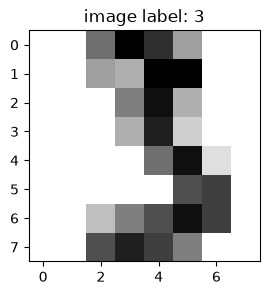

In [18]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[sample_index], cmap=plt.cm.gray_r,
           interpolation='nearest')
plt.title("image label: %d" % digits.target[sample_index]);

### Preprocessing

- Normalization
- Train / test split

In [19]:
import numpy as np
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

data = np.asarray(digits.data, dtype='float32')
target = np.asarray(digits.target, dtype='int32')

X_train, X_test, y_train, y_test = train_test_split(
    data, target, test_size=0.15, random_state=37)

# mean = 0 ; standard deviation = 1.0
scaler = preprocessing.StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# print(scaler.mean_)
# print(scaler.scale_)
(X_train.shape, y_train.shape), (X_test.shape, y_test.shape)

(((1527, 64), (1527,)), ((270, 64), (270,)))

TensorFlow provides dataset abstraction which makes it is to iterate over the data batch by batch:

In [20]:
def gen_dataset(x, y, batch_size=128):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    dataset = dataset.shuffle(buffer_size=10000, seed=42)
    dataset = dataset.batch(batch_size=batch_size)
    return dataset

In [21]:
dataset = gen_dataset(X_train, y_train)
dataset

<_BatchDataset element_spec=(TensorSpec(shape=(None, 64), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [22]:
batch_x, batch_y = next(iter(dataset))
batch_x.shape

TensorShape([128, 64])

In [23]:
 batch_y.shape

TensorShape([128])

### Build a model using TensorFlow

- Using TensorFlow, build a similar model (one hidden layer) as you previously did;
- The input will be a batch coming from X_train, and the output will be a batch of ints;
- The output do not need be normalized as probabilities, the softmax will be moved to the loss function.

In [24]:
# helper functions to use to test your randomly initialized model:

def init_weights(shape):
    return tf.Variable(tf.random.normal(shape, stddev=0.01))


def accuracy(y_pred, y):
    return np.mean(np.argmax(y_pred, axis=1) == y)


def test_model(model, x, y):
    dataset = gen_dataset(x, y)
    preds, targets = [], []

    for batch_x, batch_y in dataset:
        preds.append(model(batch_x).numpy())
        targets.append(batch_y.numpy())

    preds, targets = np.concatenate(preds), np.concatenate(targets)
    return accuracy(preds, targets)

Define your model there, and then execute the following cell to train your model.
Don't hesitate to tweak the hyperparameters.

In [25]:
# hyperparams
batch_size = 32
hid_size = 15
learning_rate = 0.5
num_epochs = 10
input_size = X_train.shape[1]
output_size = 10

tf.random.set_seed(0)


# build the model and weights
class MyModel:
    def __init__(self, input_size, hid_size, output_size):
        # randomly initialize all the internal variables of the model
        # (tf.Variable: these tensors are updated during training and
        # are tracked by tf.GradientTape)
        self.W_h = init_weights([input_size, hid_size])
        self.b_h = tf.Variable(tf.zeros([hid_size]))
        self.W_o = init_weights([hid_size, output_size])
        self.b_o = tf.Variable(tf.zeros([output_size]))

    def __call__(self, inputs):
        # forward pass with tensorflow operations: same model as in Part 1
        # (one hidden layer with a sigmoid activation).
        # It returns the logits (unnormalized predictions): the softmax is
        # applied inside the loss function (sparse_softmax_cross_entropy_with_logits)
        h = tf.sigmoid(tf.matmul(inputs, self.W_h) + self.b_h)
        return tf.matmul(h, self.W_o) + self.b_o

model = MyModel(input_size, hid_size, output_size)

In [26]:
test_model(model, X_test, y_test)

np.float64(0.0962962962962963)

The following implements a training loop in Python. Note the use of `tf.GradientTape` to automatically compute the gradients of the loss w.r.t. the different parameters of the model:

Epoch 0, train_acc = 0.3019, test_acc = 0.2704


Epoch 1, train_acc = 0.8035, test_acc = 0.7741


Epoch 2, train_acc = 0.8906, test_acc = 0.8926


Epoch 3, train_acc = 0.9352, test_acc = 0.9259


Epoch 4, train_acc = 0.9568, test_acc = 0.9519


Epoch 5, train_acc = 0.9699, test_acc = 0.9593


Epoch 6, train_acc = 0.9751, test_acc = 0.9593


Epoch 7, train_acc = 0.9784, test_acc = 0.9593


Epoch 8, train_acc = 0.9817, test_acc = 0.9556


Epoch 9, train_acc = 0.9836, test_acc = 0.9593


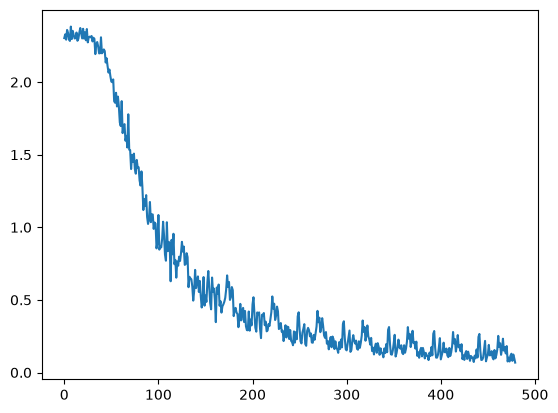

In [27]:
losses = []
for e in range(num_epochs):
    train_dataset = gen_dataset(X_train, y_train, batch_size=batch_size)

    for batch_x, batch_y in train_dataset:
        # tf.GradientTape records the activation to compute the gradients:
        with tf.GradientTape() as tape:
            logits = model(batch_x)
            loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(batch_y, logits))
            losses.append(loss.numpy())

        # Here we ask for the gradients of dL/dW_h, etc.
        dW_h, db_h, dW_o, db_o = tape.gradient(
            loss, [model.W_h, model.b_h, model.W_o, model.b_o])

        # Update the weights as a Stochastic Gradient Descent would do:
        model.W_h.assign_sub(learning_rate * dW_h)
        model.b_h.assign_sub(learning_rate * db_h)
        model.W_o.assign_sub(learning_rate * dW_o)
        model.b_o.assign_sub(learning_rate * db_o)

    train_acc = test_model(model, X_train, y_train)
    test_acc = test_model(model, X_test, y_test)
    print("Epoch {}, train_acc = {}, test_acc = {}".format(e, round(train_acc, 4), round(test_acc, 4)))

plt.plot(losses)

In [28]:
test_model(model, X_test, y_test)

np.float64(0.9592592592592593)

In [29]:
test_model(model, X_train, y_train)

np.float64(0.9836280288146693)

### Manual backpropagation vs `tf.GradientTape`

To link this part with Part 1, we compute the gradients of the loss on one mini-batch
in two ways:

1. **automatically** with `tf.GradientTape`,
2. **manually** with numpy, using the backpropagation formulas of Part 1
   (softmax + NLL, then the chain rule through the sigmoid hidden layer),
   averaged over the mini-batch.

Both must give the same values (up to float32 rounding).

In [30]:
batch_x, batch_y = next(iter(gen_dataset(X_train, y_train, batch_size=32)))

# 1) automatic differentiation
with tf.GradientTape() as tape:
    logits = model(batch_x)
    loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(batch_y, logits))
auto_grads = tape.gradient(loss, [model.W_h, model.b_h, model.W_o, model.b_o])

# 2) manual backpropagation in numpy (same formulas as in Part 1)
x = batch_x.numpy().astype(np.float64)
y_onehot = np.eye(output_size)[batch_y.numpy()]
W_h, b_h = model.W_h.numpy().astype(np.float64), model.b_h.numpy().astype(np.float64)
W_o, b_o = model.W_o.numpy().astype(np.float64), model.b_o.numpy().astype(np.float64)

z_h = x @ W_h + b_h                       # forward pass, keeping the activations
h = 1 / (1 + np.exp(-z_h))
z_o = h @ W_o + b_o
exp = np.exp(z_o - z_o.max(axis=1, keepdims=True))
y_pred = exp / exp.sum(axis=1, keepdims=True)

n = x.shape[0]
grad_z_o = (y_pred - y_onehot) / n        # d(mean NLL)/d(logits)
grad_W_o = h.T @ grad_z_o
grad_b_o = grad_z_o.sum(axis=0)
grad_h = grad_z_o @ W_o.T
grad_z_h = grad_h * h * (1 - h)           # sigmoid'(z) = sigmoid(z) * (1 - sigmoid(z))
grad_W_h = x.T @ grad_z_h
grad_b_h = grad_z_h.sum(axis=0)
manual_grads = [grad_W_h, grad_b_h, grad_W_o, grad_b_o]

for name, g_auto, g_manual in zip(["W_h", "b_h", "W_o", "b_o"], auto_grads, manual_grads):
    g_auto = g_auto.numpy()
    rel = np.linalg.norm(g_auto - g_manual) / (np.linalg.norm(g_auto) + np.linalg.norm(g_manual))
    print("%s: shape %s, relative difference = %.1e" % (name, g_auto.shape, rel))

W_h: shape (64, 15), relative difference = 1.9e-07
b_h: shape (15,), relative difference = 1.9e-07
W_o: shape (15, 10), relative difference = 1.7e-07
b_o: shape (10,), relative difference = 1.6e-07


**Conclusion.** The gradients computed by `tf.GradientTape` are the same as the ones we derived by hand in Part 1 (relative difference around 1e-7, which is float32 rounding). TensorFlow applies exactly the same chain rule. The difference is that TensorFlow **records** the operations of the forward pass on the tape and derives the backward pass automatically, while in Part 1 we had to:
- keep the intermediate activations (`z_h`, `h`) ourselves (`forward_keep_activations`),
- derive the formula of each local derivative (softmax + NLL, sigmoid),
- get every shape and transpose right (`h.T @ grad`, `grad @ W_o.T`),
- remember to average over the batch,
- verify everything with a numerical gradient check.

Here, changing the model (another activation, another layer) only requires changing the forward pass.

### Exercises (Bonus)

- add L2 regularization with $\lambda = 10^{-4}$
- train with arbitrary number of layers: only pass the layer sizes as hyperparameter to the model class constructor (`__init__` method)
- try implementing momentum
- you may use tensorboard (https://www.tensorflow.org/how_tos/summaries_and_tensorboard/) to monitor loss and display graph

We first write a model class that takes the list of the layer sizes, and a generic
training function with optional L2 regularization, momentum and TensorBoard logging.

In [31]:
class MLP:
    """MLP with an arbitrary number of layers: layer_sizes = [input, hidden_1, ..., output]."""

    def __init__(self, layer_sizes, activation=tf.sigmoid, stddev=0.01):
        """stddev: a float, or "glorot" (sqrt(2 / (n_in + n_out))), or "he" (sqrt(2 / n_in), for ReLU)."""
        self.activation = activation
        self.weights, self.biases = [], []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            if stddev == "glorot":
                std = np.sqrt(2. / (n_in + n_out))
            elif stddev == "he":
                std = np.sqrt(2. / n_in)
            else:
                std = stddev
            self.weights.append(tf.Variable(tf.random.normal([n_in, n_out], stddev=std)))
            self.biases.append(tf.Variable(tf.zeros([n_out])))

    @property
    def variables(self):
        return self.weights + self.biases

    def __call__(self, inputs):
        h = inputs
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            h = self.activation(tf.matmul(h, W) + b)
        # last layer: logits, no activation (softmax is in the loss)
        return tf.matmul(h, self.weights[-1]) + self.biases[-1]


def train(model, learning_rate=0.5, num_epochs=10, batch_size=32, l2=0., momentum=0.,
          log_dir=None, verbose=True):
    """Mini-batch SGD with optional L2 regularization, momentum and TensorBoard logging."""
    variables = model.variables
    velocities = [tf.Variable(tf.zeros_like(v)) for v in variables]
    writer = tf.summary.create_file_writer(log_dir) if log_dir else None
    history = {"loss": [], "train_acc": [], "test_acc": []}
    step = 0
    for e in range(num_epochs):
        epoch_losses = []
        for batch_x, batch_y in gen_dataset(X_train, y_train, batch_size=batch_size):
            with tf.GradientTape() as tape:
                logits = model(batch_x)
                data_loss = tf.reduce_mean(
                    tf.nn.sparse_softmax_cross_entropy_with_logits(batch_y, logits))
                # L2 penalty on the weights (not on the biases)
                l2_loss = l2 * tf.add_n([tf.reduce_sum(W ** 2) for W in model.weights])
                loss = data_loss + l2_loss
            grads = tape.gradient(loss, variables)

            # SGD with momentum (momentum = 0 gives plain SGD):
            # v <- momentum * v - lr * grad ; theta <- theta + v
            for v, velocity, g in zip(variables, velocities, grads):
                velocity.assign(momentum * velocity - learning_rate * g)
                v.assign_add(velocity)

            epoch_losses.append(data_loss.numpy())
            if writer:
                with writer.as_default():
                    tf.summary.scalar("batch/data_loss", data_loss, step=step)
                    tf.summary.scalar("batch/l2_loss", l2_loss, step=step)
            step += 1

        history["loss"].append(np.mean(epoch_losses))
        history["train_acc"].append(test_model(model, X_train, y_train))
        history["test_acc"].append(test_model(model, X_test, y_test))
        if writer:
            with writer.as_default():
                tf.summary.scalar("epoch/train_accuracy", history["train_acc"][-1], step=e)
                tf.summary.scalar("epoch/test_accuracy", history["test_acc"][-1], step=e)
                tf.summary.scalar("epoch/weights_norm",
                                  tf.sqrt(tf.add_n([tf.reduce_sum(W ** 2) for W in model.weights])),
                                  step=e)
        if verbose:
            print("Epoch %d, loss = %.4f, train_acc = %.4f, test_acc = %.4f"
                  % (e, history["loss"][-1], history["train_acc"][-1], history["test_acc"][-1]))
    if writer:
        writer.flush()
    return history


def weights_norm(model):
    return np.sqrt(sum(np.sum(W.numpy() ** 2) for W in model.weights))

Sanity check: `MLP([64, 15, 10])` is the same model as `MyModel`, and the generic training
function with `l2=0, momentum=0` is the same training loop as above.

In [32]:
tf.random.set_seed(0)
mlp = MLP([input_size, hid_size, output_size])
history = train(mlp, learning_rate=0.5, num_epochs=10)

Epoch 0, loss = 2.2814, train_acc = 0.3019, test_acc = 0.2704


Epoch 1, loss = 1.5153, train_acc = 0.8035, test_acc = 0.7741


Epoch 2, loss = 0.7920, train_acc = 0.8906, test_acc = 0.8926


Epoch 3, loss = 0.5036, train_acc = 0.9352, test_acc = 0.9259


Epoch 4, loss = 0.3512, train_acc = 0.9568, test_acc = 0.9519


Epoch 5, loss = 0.2634, train_acc = 0.9699, test_acc = 0.9593


Epoch 6, loss = 0.2104, train_acc = 0.9751, test_acc = 0.9593


Epoch 7, loss = 0.1760, train_acc = 0.9784, test_acc = 0.9593


Epoch 8, loss = 0.1520, train_acc = 0.9817, test_acc = 0.9556


Epoch 9, loss = 0.1342, train_acc = 0.9836, test_acc = 0.9593


#### L2 regularization ($\lambda = 10^{-4}$)

l2=0      train acc = 1.0000, test acc = 0.9778, final train loss (without penalty) = 0.0231, weights norm = 19.15


l2=0.0001 train acc = 0.9993, test acc = 0.9852, final train loss (without penalty) = 0.0298, weights norm = 18.02


l2=0.001  train acc = 0.9915, test acc = 0.9889, final train loss (without penalty) = 0.0958, weights norm = 13.40


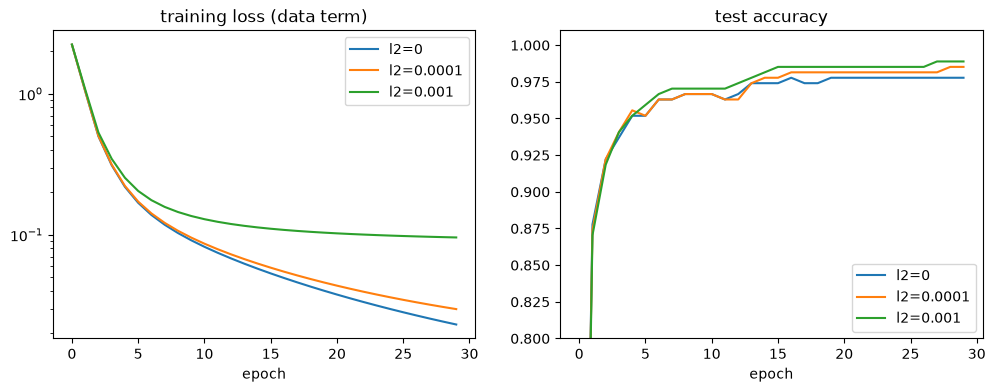

In [33]:
results = {}
for l2 in [0., 1e-4, 1e-3]:
    tf.random.set_seed(0)
    m = MLP([input_size, 50, output_size])
    h = train(m, learning_rate=0.5, num_epochs=30, l2=l2, verbose=False)
    results["l2=%g" % l2] = h
    print("l2=%-6g train acc = %.4f, test acc = %.4f, final train loss (without penalty) = %.4f, "
          "weights norm = %.2f" % (l2, h["train_acc"][-1], h["test_acc"][-1], h["loss"][-1],
                                   weights_norm(m)))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))
for label, h in results.items():
    ax0.plot(h["loss"], label=label)
    ax1.plot(h["test_acc"], label=label)
ax0.set_yscale("log"); ax0.set_title("training loss (data term)"); ax0.set_xlabel("epoch")
ax1.set_title("test accuracy"); ax1.set_ylim(0.8, 1.01); ax1.set_xlabel("epoch")
ax0.legend(); ax1.legend();

**L2 regularization.** The penalty $\lambda \sum_l \|W_l\|^2$ is simply added to the loss inside the `GradientTape`: TensorFlow differentiates it automatically (manually we would have had to add $2 \lambda W$ to each weight gradient). With $\lambda = 10^{-4}$ the weights are slightly smaller (norm 18.0 vs 19.2), the training loss is a little higher and the test accuracy goes from 97.8% to 98.5%. With $\lambda = 10^{-3}$ the effect is stronger (weights norm 13.4, test acc 98.9%, train acc no longer 100%). Regularization trades a bit of training fit for better generalization, which reduces the overfitting observed in Part 1.

#### Arbitrary number of layers

[15] sigmoid (init 0.01)             train acc = 0.9948, test acc = 0.9630


[15] sigmoid (init glorot)           train acc = 0.9961, test acc = 0.9704


[15] relu (init he)                  train acc = 0.9987, test acc = 0.9704


[50] sigmoid (init 0.01)             train acc = 0.9948, test acc = 0.9778


[50] sigmoid (init glorot)           train acc = 0.9980, test acc = 0.9815


[50] relu (init he)                  train acc = 0.9987, test acc = 0.9741


... (2 outputs left out)

[50, 20] relu (init he)              train acc = 1.0000, test acc = 0.9815


[50, 30, 20] sigmoid (init 0.01)     train acc = 0.1022, test acc = 0.0889


[50, 30, 20] sigmoid (init glorot)   train acc = 0.9823, test acc = 0.9444


[50, 30, 20] relu (init he)          train acc = 1.0000, test acc = 0.9741


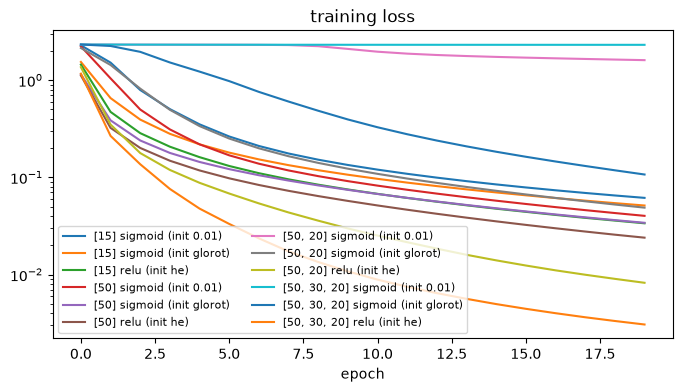

In [34]:
results = {}
configs = {
    "[15]": [input_size, 15, output_size],
    "[50]": [input_size, 50, output_size],
    "[50, 20]": [input_size, 50, 20, output_size],
    "[50, 30, 20]": [input_size, 50, 30, 20, output_size],
}
for label, sizes in configs.items():
    for act_name, act, init, lr in [("sigmoid", tf.sigmoid, 0.01, 0.5),
                                    ("sigmoid", tf.sigmoid, "glorot", 0.5),
                                    ("relu", tf.nn.relu, "he", 0.1)]:
        tf.random.set_seed(0)
        m = MLP(sizes, activation=act, stddev=init)
        h = train(m, learning_rate=lr, num_epochs=20, verbose=False)
        name = "%s %s (init %s)" % (label, act_name, init)
        results[name] = h
        print("%-36s train acc = %.4f, test acc = %.4f"
              % (name, h["train_acc"][-1], h["test_acc"][-1]))

fig, ax = plt.subplots(figsize=(8, 4))
for label, h in results.items():
    ax.plot(h["loss"], label=label)
ax.set_yscale("log"); ax.set_title("training loss"); ax.set_xlabel("epoch")
ax.legend(fontsize=8, ncol=2);

**Arbitrary number of layers.** The `MLP` class only takes the list of the layer sizes. The backward pass does not need to be written at all: `tape.gradient` handles any depth.

- With 1 hidden layer all configurations reach 96 to 98% test accuracy.
- With **2 or 3 hidden layers, sigmoid and the very small init (stddev = 0.01) do not learn at all** (36% and 9% test accuracy). This is the **vanishing gradient** problem: each layer multiplies the gradient by a small weight matrix (0.01) and by $\sigma'(z) \le 0.25$, so the gradient that reaches the first layers is tiny.
- With a **Glorot** init (stddev = $\sqrt{2/(n_{in}+n_{out})}$) the same deep sigmoid networks train well. **ReLU with He init** works best for the deeper networks (98.2% with [50, 20]), because $\text{ReLU}'(z) = 1$ for active units and the gradient is not shrunk at every layer.

Automatic differentiation computes *correct* gradients, but it does not make them *useful*: the initialization and the activation functions still matter.

#### Momentum

Implemented in `train` with one extra `tf.Variable` (the velocity) per parameter:

$$
v \leftarrow \mu \, v - \eta \, \nabla_\theta L \qquad \theta \leftarrow \theta + v
$$

We compare with a smaller learning rate (0.05) to see the effect clearly.

momentum=0    final loss = 1.0155, train acc = 0.8193, test acc = 0.7815


momentum=0.5  final loss = 0.4121, train acc = 0.9319, test acc = 0.9185


momentum=0.9  final loss = 0.0604, train acc = 0.9948, test acc = 0.9593


keras SGD(momentum=0.9): train acc = 0.9948, test acc = 0.9593


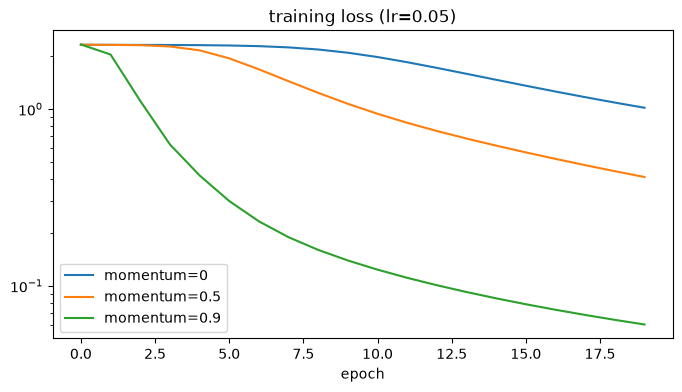

In [35]:
results = {}
for momentum in [0., 0.5, 0.9]:
    tf.random.set_seed(0)
    m = MLP([input_size, hid_size, output_size])
    h = train(m, learning_rate=0.05, num_epochs=20, momentum=momentum, verbose=False)
    results["momentum=%g" % momentum] = h
    print("momentum=%-4g final loss = %.4f, train acc = %.4f, test acc = %.4f"
          % (momentum, h["loss"][-1], h["train_acc"][-1], h["test_acc"][-1]))

# Same thing with the built-in Keras optimizer (it implements the same update rule)
tf.random.set_seed(0)
m = MLP([input_size, hid_size, output_size])
optimizer = tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9)
for e in range(20):
    for batch_x, batch_y in gen_dataset(X_train, y_train, batch_size=32):
        with tf.GradientTape() as tape:
            loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(
                batch_y, m(batch_x)))
        optimizer.apply_gradients(zip(tape.gradient(loss, m.variables), m.variables))
print("keras SGD(momentum=0.9): train acc = %.4f, test acc = %.4f"
      % (test_model(m, X_train, y_train), test_model(m, X_test, y_test)))

fig, ax = plt.subplots(figsize=(8, 4))
for label, h in results.items():
    ax.plot(h["loss"], label=label)
ax.set_yscale("log"); ax.set_title("training loss (lr=0.05)"); ax.set_xlabel("epoch")
ax.legend();

**Momentum.** With a small learning rate (0.05), plain SGD is slow (loss 1.02 after 20 epochs, test acc 78%). Momentum 0.5 already helps a lot, and momentum 0.9 converges much faster (loss 0.06, test acc 96%). The velocity accumulates the past gradients, so the effective step is about lr / (1 - mu).

Our manual implementation gives **exactly the same result** as `tf.keras.optimizers.SGD(momentum=0.9)` (same accuracies), which confirms that it implements the same update rule. In practice we would use the built-in optimizers (`SGD`, `Adam`, ...) with `optimizer.apply_gradients`.

#### TensorBoard

`train(..., log_dir=...)` writes the losses and accuracies with `tf.summary`. To also
display the **graph** of the model, the forward pass and the loss are wrapped in a
`tf.function` (TensorFlow then traces them into a static graph) and the trace is exported
with `tf.summary.trace_on` / `tf.summary.trace_export`.

In [36]:
import datetime
import os

log_dir = os.path.join("logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))

tf.random.set_seed(0)
m = MLP([input_size, 50, output_size])
history = train(m, learning_rate=0.5, num_epochs=15, l2=1e-4, momentum=0.,
                log_dir=os.path.join(log_dir, "train"), verbose=False)
print("final test acc = %.4f" % history["test_acc"][-1])


# Export the computation graph of the forward pass + loss
@tf.function
def compute_loss(batch_x, batch_y):
    logits = m(batch_x)
    return tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(batch_y, logits))


graph_writer = tf.summary.create_file_writer(os.path.join(log_dir, "graph"))
batch_x, batch_y = next(iter(gen_dataset(X_train, y_train)))
tf.summary.trace_on(graph=True)
compute_loss(batch_x, batch_y)
with graph_writer.as_default():
    tf.summary.trace_export(name="mlp_loss", step=0)

print("TensorBoard logs written to", log_dir)

final test acc = 0.9778


TensorBoard logs written to logs\20261114-005951


To open TensorBoard in the notebook (or run `tensorboard --logdir logs` in a terminal):

In [37]:
# %load_ext tensorboard
# %tensorboard --logdir logs